## Black Friday Sales Analysis

### 1. Dataset Selection

The Black Friday Sales dataset was selected from Kaggle, which is a widely used
and reliable platform for datasets.

This dataset contains information about customers, products, customer
demographics, product categories, and purchase amounts during Black Friday
sales.

The dataset was selected because it provides useful information for analyzing
customer purchasing behavior, product preferences, and sales patterns.

For this project, a sample of 10,000 records will be used for exploratory data
analysis to make the analysis manageable while retaining the important
characteristics of the dataset.

#### Why did I select this dataset?

The Black Friday Sales dataset was selected because it contains both
categorical and numerical variables, making it suitable for univariate,
bivariate, and multivariate exploratory data analysis.

It allows us to study customer demographics, product categories, city
categories, and purchase amounts and identify meaningful patterns in customer
purchasing behavior.

### Data Loading
#### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Load the dataset

In [5]:
df = pd.read_csv("BlackFriday_records.csv")

In [7]:
df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1001062,P00351342,M,51-55,19,C,3,0,1,2.0,16.0,19142
1,1005172,P00237542,F,36-45,11,B,1,0,1,15.0,16.0,15513
2,1000415,P00116242,F,36-45,0,A,2,1,8,15.0,NaN,7802
3,1000496,P00016742,M,18-25,4,A,3,0,1,15.0,16.0,15455
4,1002010,P00002242,M,18-25,4,B,0,0,6,8.0,16.0,4492


#### Observation

The dataset was successfully loaded using the Pandas library. The first five
records show that the dataset contains customer, product, demographic, and
purchase-related information.

### Data Observation

In [348]:
df.head()

,user_id,product_id,gender,age,occupation,city_category,stay_in_current_city_years,marital_status,product_category_1,product_category_2,product_category_3,purchase
0,1001062,P00351342,M,51-55,19,C,3,0,1,2.0,16.0,19142
1,1005172,P00237542,F,36-45,11,B,1,0,1,15.0,16.0,15513
2,1000415,P00116242,F,36-45,0,A,2,1,8,15.0,0.0,7802
3,1000496,P00016742,M,18-25,4,A,3,0,1,15.0,16.0,15455
4,1002010,P00002242,M,18-25,4,B,0,0,6,8.0,16.0,4492


#### Observation

The first five records provide an initial understanding of the dataset. The
dataset contains customer identifiers, product information, demographic
attributes, and purchase amounts.

In [9]:
df.shape

(10000, 12)

#### Observation

The original dataset contains a large number of records and multiple features.
Since this project requires a manageable dataset, 10,000 records will be used
for the analysis.

In [11]:
df.columns

Index(['User_ID', 'Product_ID', 'Gender', 'Age', 'Occupation', 'City_Category',
       'Stay_In_Current_City_Years', 'Marital_Status', 'Product_Category_1',
       'Product_Category_2', 'Product_Category_3', 'Purchase'],
      dtype='object')

#### Observation

The column names were examined to understand the features available in the
dataset. The columns represent customer details, product information,
demographic characteristics, and purchase amount.

### Column Name Verification & Lowercase

In [219]:
df.columns = df.columns.str.lower()
df.columns

Index(['user_id', 'product_id', 'gender', 'age', 'occupation', 'city_category',
       'stay_in_current_city_years', 'marital_status', 'product_category_1',
       'product_category_2', 'product_category_3', 'purchase'],
      dtype='object')

#### Observation

All column names have been converted to lowercase. This provides a consistent
naming convention and makes the columns easier to reference during analysis.

### Dataset Information

In [271]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     10000 non-null  int64  
 1   product_id                  10000 non-null  object 
 2   gender                      10000 non-null  object 
 3   age                         10000 non-null  object 
 4   occupation                  10000 non-null  int64  
 5   city_category               10000 non-null  object 
 6   stay_in_current_city_years  10000 non-null  object 
 7   marital_status              10000 non-null  int64  
 8   product_category_1          10000 non-null  int64  
 9   product_category_2          10000 non-null  float64
 10  product_category_3          10000 non-null  float64
 11  purchase                    10000 non-null  int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 937.6+ KB


#### Observation

The dataset contains both numerical and categorical variables. The information
also shows the data types of each column and helps identify columns that may
require further cleaning or preparation.

### Statistical Summary

In [279]:
df.describe()

,user_id,occupation,marital_status,product_category_1,product_category_2,product_category_3,purchase
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.003039e+06,8.190600,0.409700,5.401900,6.818800,3.843200,9268.608600
std,1.735904e+03,6.541938,0.491803,3.910205,6.253069,6.274803,5059.625703
min,1.000001e+06,0.000000,0.000000,1.000000,0.000000,0.000000,12.000000
25%,1.001510e+06,2.000000,0.000000,1.000000,0.000000,0.000000,5469.000000
50%,1.003068e+06,7.000000,0.000000,5.000000,5.500000,0.000000,8033.000000
75%,1.004497e+06,14.000000,1.000000,8.000000,14.000000,8.000000,12054.000000
max,1.006040e+06,20.000000,1.000000,20.000000,18.000000,18.000000,23942.000000


#### Observation

The statistical summary provides information such as count, mean, standard
deviation, minimum, maximum, and quartile values for numerical variables.
This helps us understand the distribution and range of the numerical data.

### Missing Values

In [221]:
df.isnull().sum()

user_id                       0
product_id                    0
gender                        0
age                           0
occupation                    0
city_category                 0
stay_in_current_city_years    0
marital_status                0
product_category_1            0
product_category_2            0
product_category_3            0
purchase                      0
dtype: int64

#### Observation

The missing-value check shows that there are no missing values in any column of
the dataset. Therefore, no missing-value treatment or imputation was required.

### Duplicate Values

In [223]:
df.duplicated().sum()

0

#### Observation

The duplicate-value check shows that there are no duplicate records in the
dataset. Therefore, no duplicate records were removed, and the dataset can be
used for further analysis without duplicate observations affecting the results.

### Outlier Detection & Treatment

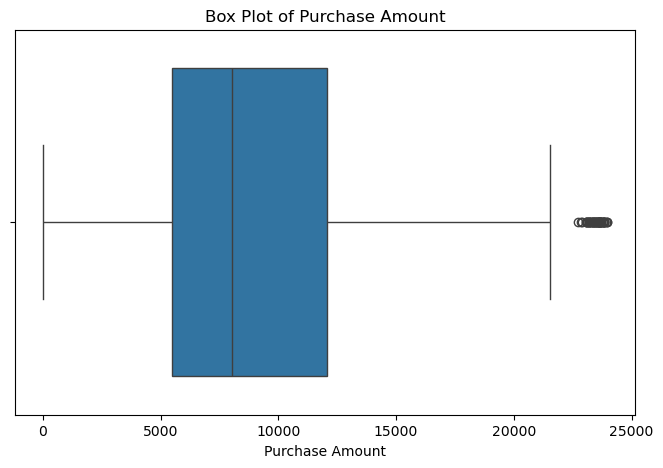

In [288]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['purchase'])
plt.title('Box Plot of Purchase Amount')
plt.xlabel('Purchase Amount')
plt.show()

#### Observation

The box plot was used to identify unusually high or low purchase values.
Potential outliers can be observed beyond the whiskers of the box plot.

In [232]:
Q1 = df['purchase'].quantile(0.25)
Q3 = df['purchase'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower limit:", lower)
print("Upper limit:", upper)

Lower limit: -4408.5
Upper limit: 21931.5


#### Observation

The IQR method was used to calculate the lower and upper bounds for detecting
potential outliers in purchase amounts.

### Imbalance Check

In [241]:
df['gender'].value_counts()

gender
M    7559
F    2441
Name: count, dtype: int64

#### Observation

The gender distribution was examined to determine whether the categories are
balanced. The number of observations in each category shows whether one
category is considerably more represented than another.

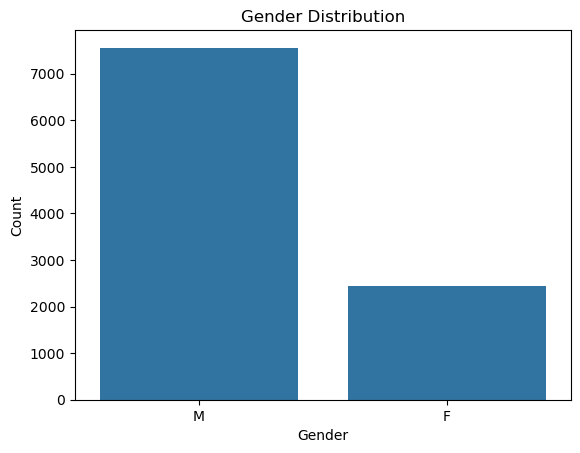

In [296]:
sns.countplot(x='gender', data=df)
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

#### Observation

The count plot visually compares the number of male and female customers.
It helps identify whether the gender distribution is balanced or imbalanced.

In [243]:
df['age'].value_counts()

age
26-35    4013
36-45    1941
18-25    1851
46-50     834
51-55     712
55+       388
0-17      261
Name: count, dtype: int64

#### Oberservation
we have different count from different age group . the highest count is from 26-35 age group they are purchasing more.

### Data Cleaning Summary

#### Missing Values
Missing values were identified and handled appropriately based on the nature
of each variable.

#### Duplicate Records
Duplicate records were checked and removed if present. This prevents repeated
observations from affecting the analysis.

#### Outliers
Outliers were detected using box plots and the IQR method. The treatment was
performed based on the distribution of the purchase variable.

#### Imbalance
The distribution of important categorical variables was checked using value
counts and visualizations. Since this is an EDA project and not a classification
model, no resampling technique was required.

### Univariate Analysis

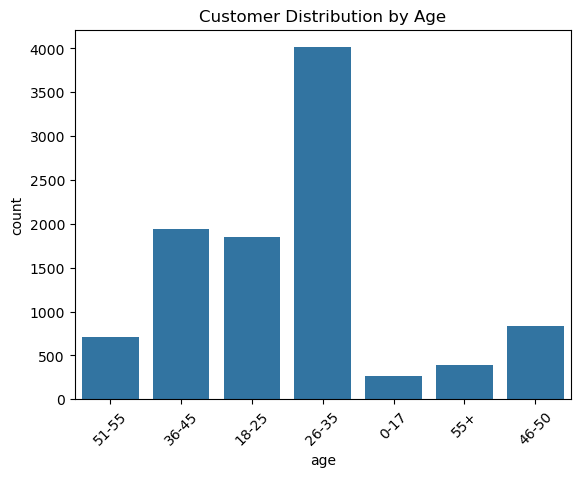

In [304]:
sns.countplot(x='age', data=df)
plt.title('Customer Distribution by Age')
plt.xticks(rotation=45)
plt.show()

#### Observation

The plot shows the distribution of customers across different age groups.
It was used to identify which age groups have the highest representation in
the dataset.

### Bivariate Analysis
Bivariate analysis is used to study the relationship between two variables.
In this analysis, purchase amount is compared with different customer and
product-related variables to identify differences in purchasing behavior.

We'll compare two variables:
- Gender vs Purchase
- Age vs Purchase
- City vs Purchase
- Marital Status vs Purchase
- Product Category vs Purchase

#### Gender vs Purchase
**Why this plot?**

A box plot is used to compare the distribution of purchase amounts between
male and female customers. It helps identify differences in the median,
spread, and overall purchasing behavior between the two gender groups.

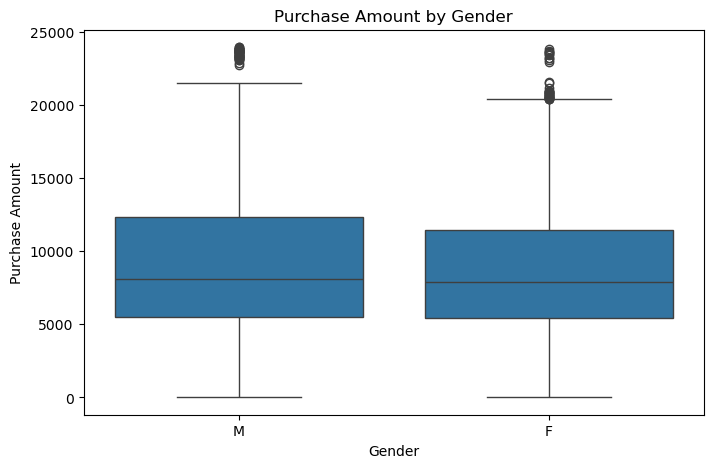

In [311]:
plt.figure(figsize=(8,5))
sns.boxplot(x='gender', y='purchase', data=df)
plt.title('Purchase Amount by Gender')
plt.xlabel('Gender')
plt.ylabel('Purchase Amount')
plt.show()

#### Observation

The box plot shows the distribution of purchase amounts for male and female
customers. The median purchase amount and spread can be compared between the
two groups.

**Insight:** The analysis helps identify whether purchasing behavior differs
between male and female customers.

#### Age vs Purchase

**Why this plot?**

A bar plot is used to compare the average purchase amount across different
age groups. It helps identify which age groups have higher or lower average
spending.

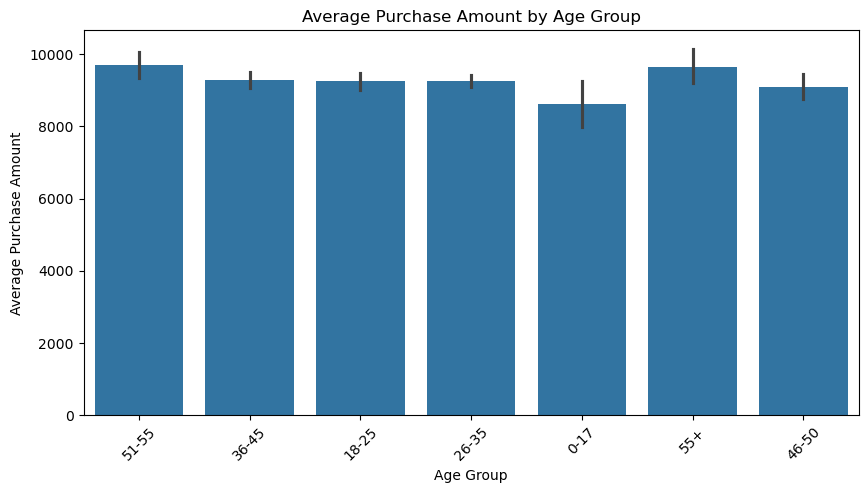

In [317]:
plt.figure(figsize=(10,5))
sns.barplot(x='age', y='purchase', data=df)
plt.title('Average Purchase Amount by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Purchase Amount')
plt.xticks(rotation=45)
plt.show()

### Observation

The bar plot compares the average purchase amount across different age
groups. Differences in the height of the bars indicate differences in
average spending between age groups.

**Insight:** The plot helps identify the age groups that contribute to higher
average purchase amounts.

#### City Category vs Purchase

**Why this plot?**

A bar plot is used to compare the average purchase amount across different
city categories. This helps determine whether customer spending varies
between city categories.

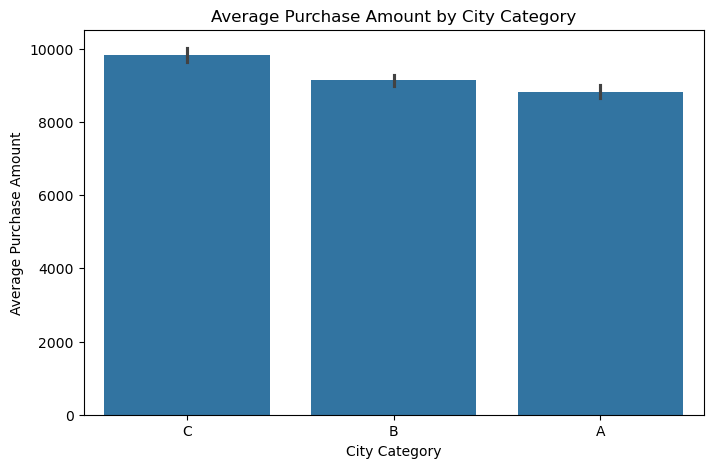

In [322]:
plt.figure(figsize=(8,5))
sns.barplot(x='city_category', y='purchase', data=df)
plt.title('Average Purchase Amount by City Category')
plt.xlabel('City Category')
plt.ylabel('Average Purchase Amount')
plt.show()

#### Observation

The bar plot shows the average purchase amount for each city category.
Differences in the bar heights indicate variations in average spending
across city categories.

**Insight:** The analysis helps identify which city category has the highest
average customer spending.

#### Marital Status vs Purchase

**Why this plot?**

A bar plot is used to compare the average purchase amount between married and
unmarried customers. It helps determine whether marital status is associated
with differences in customer spending.

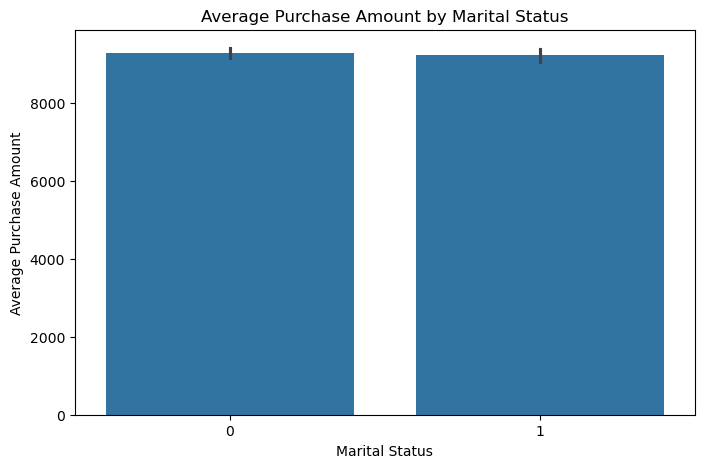

In [324]:
plt.figure(figsize=(8,5))
sns.barplot(x='marital_status', y='purchase', data=df)
plt.title('Average Purchase Amount by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Average Purchase Amount')
plt.show()

#### Observation

The bar plot compares the average purchase amount between the two marital
status categories. The difference in bar heights indicates differences in
average spending.

**Insight:** The analysis helps understand whether purchasing behavior varies
between married and unmarried customers.

#### Product Category vs Purchase

**Why this plot?**

A bar plot is used to compare the average purchase amount across product
categories. It helps identify which product categories have higher or lower
average purchase values.

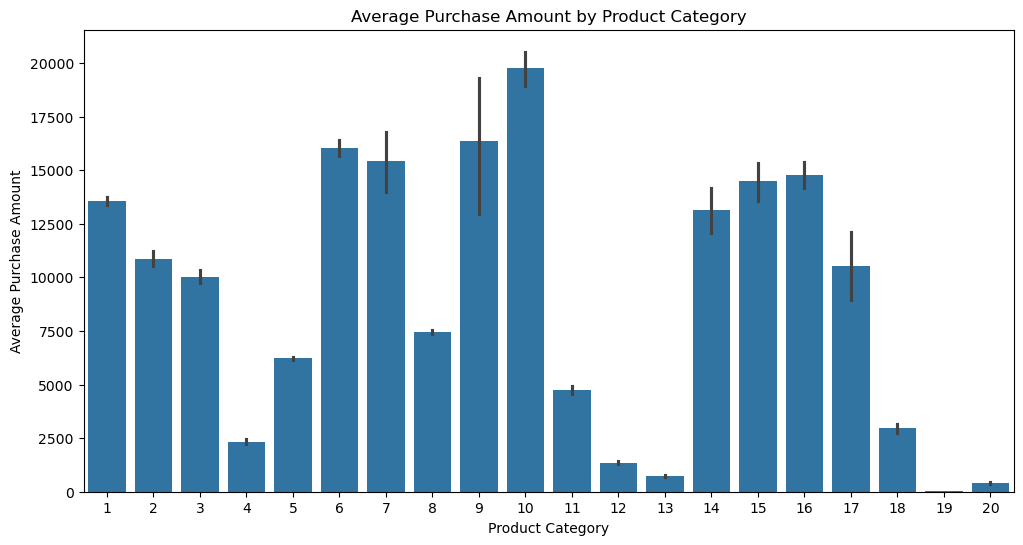

In [326]:
plt.figure(figsize=(12,6))
sns.barplot(x='product_category_1', y='purchase', data=df)
plt.title('Average Purchase Amount by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Average Purchase Amount')
plt.show()

#### Observation

The bar plot compares the average purchase amount across different product
categories. The height of each bar represents the average purchase amount
for that category.

**Insight:** The analysis helps identify product categories associated with
higher average purchase amounts.

### Multivariate Analysis

#### Age + Gender + Purchase

**Why this plot?**

A grouped bar plot is used to compare the average purchase amount across age
groups for male and female customers. It helps understand how age and gender
together influence purchasing behavior.

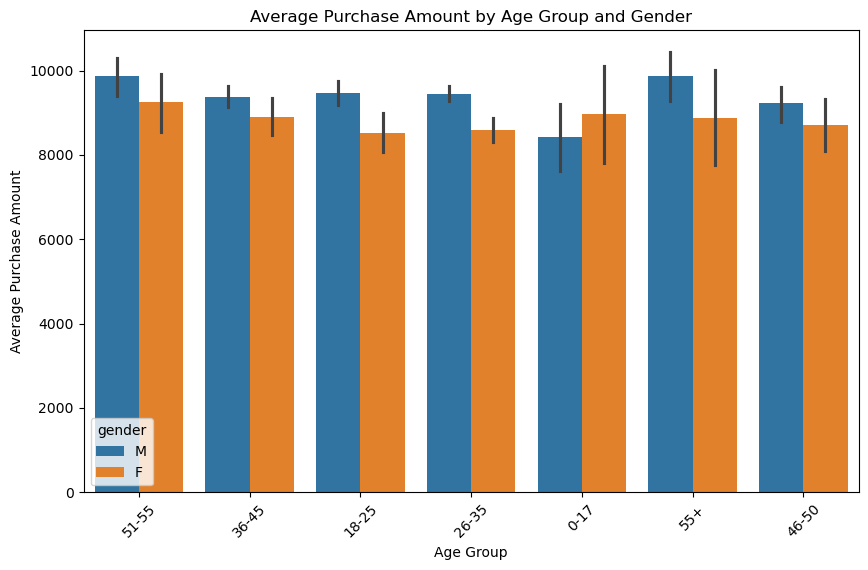

In [329]:
plt.figure(figsize=(10,6))

sns.barplot(data=df, x='age', y='purchase', hue='gender')

plt.title('Average Purchase Amount by Age Group and Gender')
plt.xlabel('Age Group')
plt.ylabel('Average Purchase Amount')
plt.xticks(rotation=45)
plt.show()

#### Observation

The plot compares the average purchase amount across different age groups
for male and female customers.

**Insight:** The comparison helps identify differences in purchasing behavior
based on the combination of age group and gender.

#### City Category + Gender + Purchase

**Why this plot?**

A grouped bar plot is used to compare average purchase amounts across city
categories for male and female customers. It helps understand whether city
category and gender together are associated with differences in spending.

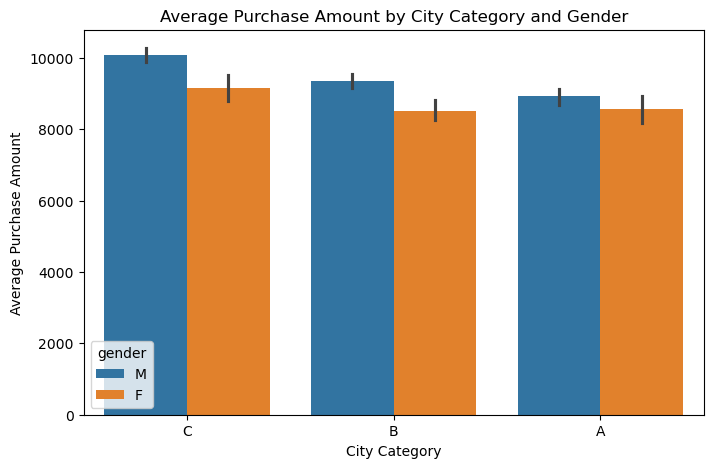

In [331]:
plt.figure(figsize=(8,5))

sns.barplot(data=df, x='city_category', y='purchase', hue='gender')

plt.title('Average Purchase Amount by City Category and Gender')
plt.xlabel('City Category')
plt.ylabel('Average Purchase Amount')
plt.show()

#### Observation

The plot compares the average purchase amount for male and female customers
across different city categories.

**Insight:** The analysis helps identify how purchasing behavior varies when
city category and gender are considered together.

#### Age + City Category + Purchase

**Why this plot?**

A grouped bar plot is used to compare average purchase amounts across age
groups and city categories. It helps examine purchasing behavior using three
variables simultaneously.

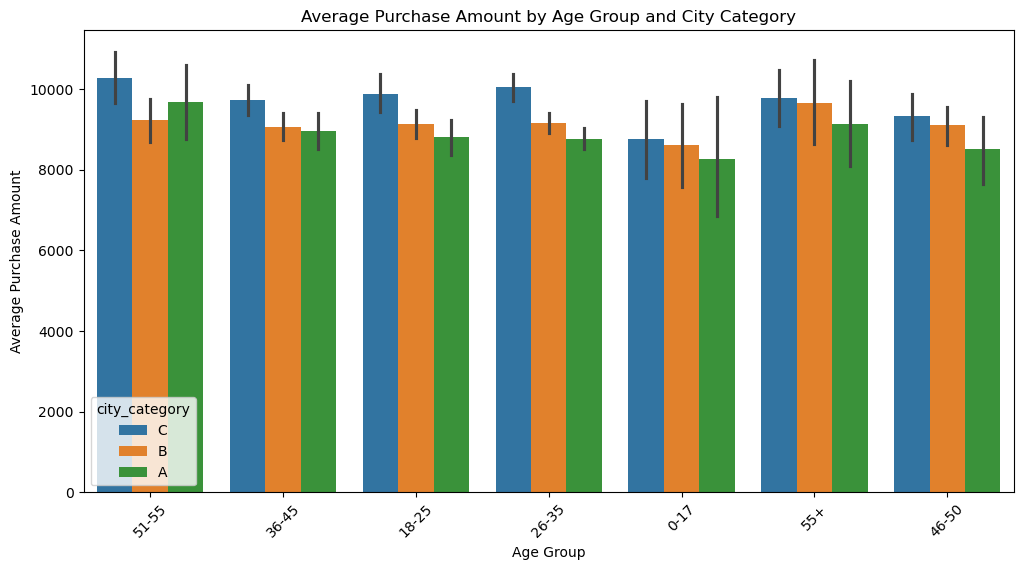

In [333]:
plt.figure(figsize=(12,6))

sns.barplot(data=df, x='age', y='purchase', hue='city_category')

plt.title('Average Purchase Amount by Age Group and City Category')
plt.xlabel('Age Group')
plt.ylabel('Average Purchase Amount')
plt.xticks(rotation=45)
plt.show()

#### Observation

The plot compares average purchase amounts across age groups and city
categories.

**Insight:** The analysis helps identify combinations of age groups and city
categories associated with higher or lower average purchasing amounts.

### Pivot Tables

#### Pivot Table 1 — Age Group and Gender

**Why this pivot table?**

This pivot table is used to compare the average purchase amount for male and
female customers across different age groups. It makes it easier to identify
differences in spending patterns between age and gender groups.

In [336]:
pivot1 = pd.pivot_table(
    df,
    values='purchase',
    index='age',
    columns='gender',
    aggfunc='mean'
)

pivot1

gender,F,M
age,,
0-17,8970.365591,8419.333333
18-25,8526.060538,9467.612811
26-35,8592.691501,9455.728431
36-45,8904.339326,9375.645722
46-50,8702.254545,9219.542345
51-55,9247.147959,9865.571705
55+,8873.659091,9872.536667


#### Observation

The pivot table shows the average purchase amount for male and female
customers across different age groups.

**Insight:** It helps identify which age and gender groups have relatively
higher or lower average purchase amounts.

#### Pivot Table 2 — City Category and Gender

**Why this pivot table?**

This pivot table is used to compare average purchase amounts across city
categories for male and female customers. It helps understand purchasing
behavior based on both location category and gender.

In [338]:
pivot2 = pd.pivot_table(
    df,
    values='purchase',
    index='city_category',
    columns='gender',
    aggfunc='mean'
)

pivot2

gender,F,M
city_category,,
A,8550.684127,8914.452358
B,8521.058541,9339.987717
C,9141.843953,10065.672593


In [ ]:
### Observation

The pivot table compares the average purchase amount of male and female
customers across different city categories.

**Insight:** It helps identify which city category and gender combination
has relatively higher average spending.

In [ ]:
### Pivot Table 3 — Product Category Analysis

**Why this pivot table?**

This pivot table is used to analyze product categories using purchase count,
average purchase amount, and total purchase amount. It provides a detailed
summary of product category performance.

In [340]:
pivot3 = pd.pivot_table(
    df,
    values='purchase',
    index='product_category_1',
    aggfunc=['count', 'mean', 'sum']
)

pivot3

,count,mean,sum
,purchase,purchase,purchase
product_category_1,,,
1,2551,13561.252842,34594756
2,426,10855.065728,4624258
3,351,10034.789174,3522211
4,202,2334.173267,471503
5,2784,6230.186782,17344840
6,400,16039.365000,6415746
7,50,15415.320000,770766
8,2033,7450.376291,15146615


#### Observation

The pivot table summarizes each product category using the number of
purchases, average purchase amount, and total purchase amount.

**Insight:** It helps identify product categories with higher purchase
frequency, higher average spending, and higher overall purchase value.

### Final Key Insights

#### 1. Customer Demographics
The dataset contains customers from different age groups and both male and
female customers. This provides useful information for understanding customer
demographics.

#### 2. Purchase Behavior by Gender
The analysis shows differences in purchase amounts between male and female
customers. Gender can therefore be considered when studying customer
purchasing behavior.

#### 3. Purchase Behavior by Age
Different age groups show differences in their average purchase amounts.
Certain age groups contribute relatively higher average spending.

#### 4. City Category Analysis
Average purchase amounts vary across different city categories. This indicates
that customer spending behavior can differ based on city category.

#### 5. Marital Status
The analysis shows differences in average purchase amounts between married and
unmarried customers. This provides an additional demographic perspective on
purchasing behavior.

#### 6. Product Category
Different product categories have different purchase frequencies, average
purchase amounts, and total purchase values. Product category is therefore an
important factor in analyzing sales performance.

#### 7. Combined Analysis
Multivariate analysis shows that purchasing behavior can vary when multiple
factors such as age, gender, and city category are considered together.

#### 8. Overall Finding
The EDA shows that customer demographics, location, and product categories
are useful factors for understanding purchasing behavior in the Black Friday
sales dataset.

### Conclusion

The Black Friday Sales dataset was selected to analyze customer purchasing
behavior and understand the factors associated with sales performance.

The dataset was cleaned and prepared by checking its structure, column names,
missing values, duplicate records, outliers, and class distribution. The
analysis was performed using univariate, bivariate, and multivariate
exploratory data analysis techniques.

The EDA helped identify purchasing patterns based on customer demographics
such as age, gender, marital status, and city category, as well as product
categories. Pivot tables were also used to summarize and compare purchase
amounts across different customer and product groups.

Overall, the analysis provides useful insights into customer purchasing
behavior during Black Friday sales and can help businesses understand
customer segments and product categories with stronger sales performance.